<a href="https://colab.research.google.com/github/HONGSAHUN/AI-Class/blob/main/Week10_1109/finance_1109.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
!pip install finance-datareader

import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [62]:
samsung = fdr.DataReader('005930', '2016')
print(samsung)

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195000  187000  194500   9911072  0.005168

[2660 rows x 6 columns]


In [63]:
openValues = samsung[['Open']]
print(openValues)

              Open
Date              
2016-01-04   25200
2016-01-05   24040
2016-01-06   24160
2016-01-07   23320
2016-01-08   23260
...            ...
2026-11-03  220500
2026-11-04  226500
2026-11-05  213000
2026-11-06  180000
2026-11-09  187200

[2660 rows x 1 columns]


In [64]:
from sklearn.preprocessing import MinMaxScaler

WINDOW = 30

# 날짜순 원본 데이터
openValues = openValues.sort_index()
data = openValues.to_numpy(dtype=np.float32)

# 먼저 시간순으로 80% / 20% 분리
split = int(len(data) * 0.8)
train_data = data[:split]
test_data = data[split:]

# 학습 데이터에만 스케일러를 맞춤
scaler = MinMaxScaler()
train_data = scaler.fit_transform(train_data)
test_data = scaler.transform(test_data)

# 각 구간 안에서 입력과 정답 생성
X_train, y_train = make_sample(train_data, WINDOW)
X_test, y_test = make_sample(test_data, WINDOW)

print("학습:", X_train.shape, y_train.shape)
print("테스트:", X_test.shape, y_test.shape)

학습: (2098, 30, 1) (2098, 1)
테스트: (502, 30, 1) (502, 1)


In [65]:
def make_sample(data, window):
  train = []
  target = []

  for i in range(len(data) - window):
    train.append(data[i:i+window])
    target.append(data[i+window])
  return np.array(train), np.array(target)

WINDOW = 30
X_train, y_train = make_sample(train_data, WINDOW)

In [66]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

model = Sequential()
model.add(LSTM(16,
               input_shape=(X_train.shape[1], 1),
               activation='tanh',
               return_sequences=False)
)
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [67]:
model.compile(optimizer = 'adam', loss = 'mean_squared_error')
model.fit(X_train, y_train, epochs = 100, batch_size = 16)

Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.1051
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0019
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0014
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0013
Epoch 5/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0013
Epoch 6/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0013
Epoch 7/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0013    
Epoch 8/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0013
Epoch 9/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0012
Epoch 10/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0011
Epoch 11/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0011    
Epoch 12/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0011
Epoch 13/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0011
Epoch 14/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0010    
Epoch 15/100
132/132 ━━━━━━━━━━

In [68]:
X_test, y_test = make_sample(test_data, WINDOW)
pred = model.predict(X_test)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


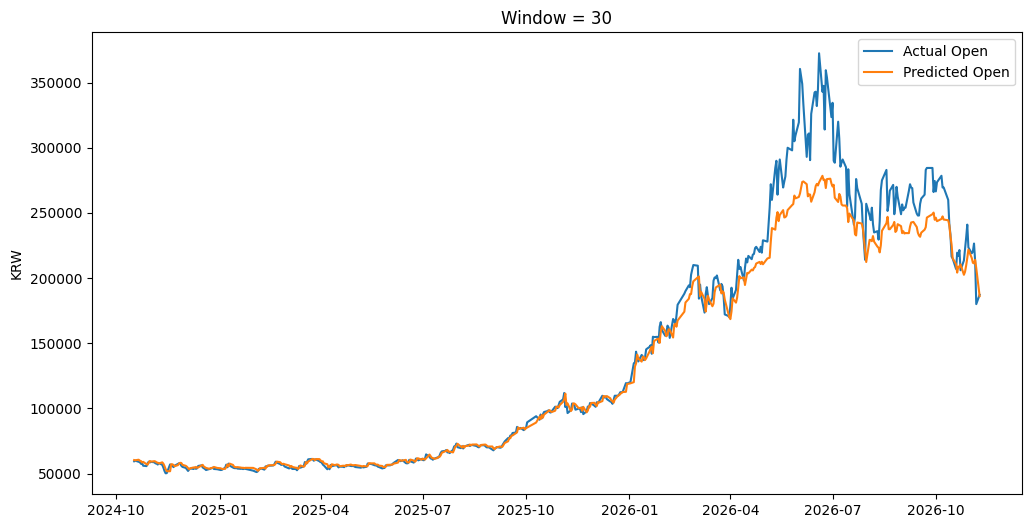

In [69]:
import matplotlib.pyplot as plt

actual_price = scaler.inverse_transform(y_test)
predicted_price = scaler.inverse_transform(pred)

dates = openValues.index[split + WINDOW:]

plt.figure(figsize=(12, 6))
plt.plot(dates, actual_price.ravel(), label='Actual Open')
plt.plot(dates, predicted_price.ravel(), label='Predicted Open')
plt.title(f'Window = {WINDOW}')
plt.ylabel('KRW')
plt.legend()
plt.show()

Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0048
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 7.6812e-04
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.1476e-04
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.7695e-04
Epoch 5/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.6879e-04
Epoch 6/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.6119e-04
Epoch 7/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.1384e-04
Epoch 8/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.8585e-04
Epoch 9/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.6367e-04
Epoch 10/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.5035e-04
Epoch 11/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.4405e-04
Epoch 12/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.3152e-04
Epoch 13/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.2680e-04
Epoch 14/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5

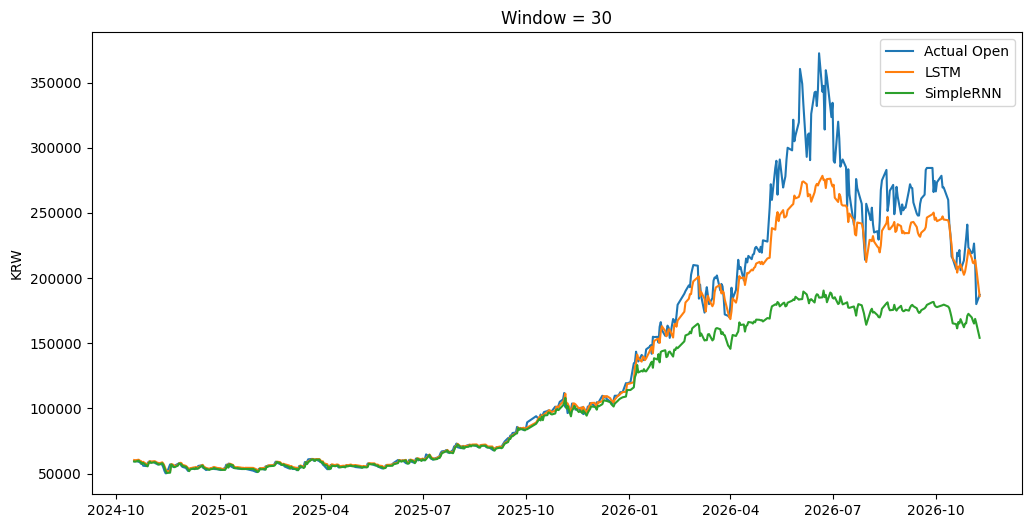

In [71]:
from tensorflow.keras import Input
from tensorflow.keras.layers import SimpleRNN

# SimpleRNN 모델 생성
model_rnn = Sequential([
    Input(shape=(WINDOW, 1)),
    SimpleRNN(16, activation='tanh'),
    Dense(1)
])

# 기존 LSTM과 같은 조건으로 학습
model_rnn.compile(optimizer='adam', loss='mean_squared_error')
model_rnn.fit(X_train, y_train, epochs=100, batch_size=16)

# 예측
pred_rnn = model_rnn.predict(X_test)

# 원 단위로 복원
actual_price = scaler.inverse_transform(y_test)
lstm_price = scaler.inverse_transform(pred)
rnn_price = scaler.inverse_transform(pred_rnn)

# 같은 날짜에서 비교
dates = openValues.index[split + WINDOW:]

plt.figure(figsize=(12, 6))
plt.plot(dates, actual_price.ravel(), label='Actual Open')
plt.plot(dates, lstm_price.ravel(), label='LSTM')
plt.plot(dates, rnn_price.ravel(), label='SimpleRNN')
plt.title(f'Window = {WINDOW}')
plt.ylabel('KRW')
plt.legend()
plt.show()